<a href="https://colab.research.google.com/github/DaviComerio/trabalho-mineracao-de-dados/blob/main/codigo/notebooks/02_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - SVM
Trabalho Prático de Mineração de Dados, Grupo 8

Base: Predict Students' Dropout and Academic Success

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

url = "https://raw.githubusercontent.com/DaviComerio/trabalho-mineracao-de-dados/main/data/data.csv"
dataset = pd.read_csv(url, sep=";")
dataset.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [11]:
print(dataset.isnull().sum().sum())
print(dataset.duplicated().sum())

y = dataset['Target']
X = dataset.drop('Target', axis='columns')

0
0


In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def avaliar(modelo, X, y):
    metricas = {"acc": [], "prec": [], "rec": [], "f1": []}
    y_true_all, y_pred_all = [], []
    for tr, te in skf.split(X, y):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X.iloc[tr])
        X_te = scaler.transform(X.iloc[te])
        modelo.fit(X_tr, y.iloc[tr])
        pred = modelo.predict(X_te)
        metricas["acc"].append(accuracy_score(y.iloc[te], pred))
        metricas["prec"].append(precision_score(y.iloc[te], pred, average="macro"))
        metricas["rec"].append(recall_score(y.iloc[te], pred, average="macro"))
        metricas["f1"].append(f1_score(y.iloc[te], pred, average="macro"))
        y_true_all.extend(y.iloc[te]); y_pred_all.extend(pred)
    return metricas, y_true_all, y_pred_all

In [13]:
configs_svm = {
    "linear C=1":  SVC(kernel='linear', C=1),
    "rbf C=1":     SVC(kernel='rbf', C=1, gamma='scale'),
    "rbf C=10":    SVC(kernel='rbf', C=10, gamma='scale'),
    "poly C=1":    SVC(kernel='poly', C=1, gamma='scale'),
}

linhas, previsoes = [], {}
for nome, modelo in configs_svm.items():
    m, yt, yp = avaliar(modelo, X, y)
    previsoes[nome] = (yt, yp)
    linhas.append({"Config": nome,
                   "Acurácia": f"{np.mean(m['acc']):.4f} ± {np.std(m['acc']):.4f}",
                   "Precisão (macro)": f"{np.mean(m['prec']):.4f}",
                   "Revocação (macro)": f"{np.mean(m['rec']):.4f}",
                   "F1 (macro)": f"{np.mean(m['f1']):.4f}"})
resumo = pd.DataFrame(linhas)
resumo

,Config,Acurácia,Precisão (macro),Revocação (macro),F1 (macro)
0,linear C=1,0.7640 ± 0.0074,0.7100,0.6725,0.6829
1,rbf C=1,0.7611 ± 0.0066,0.7117,0.6653,0.6767
2,rbf C=10,0.7495 ± 0.0117,0.6841,0.6651,0.6709
3,poly C=1,0.7161 ± 0.0051,0.6674,0.5868,0.5854


              precision    recall  f1-score   support

     Dropout       0.84      0.73      0.78      1421
    Enrolled       0.51      0.35      0.42       794
    Graduate       0.78      0.93      0.85      2209

    accuracy                           0.76      4424
   macro avg       0.71      0.67      0.68      4424
weighted avg       0.75      0.76      0.75      4424



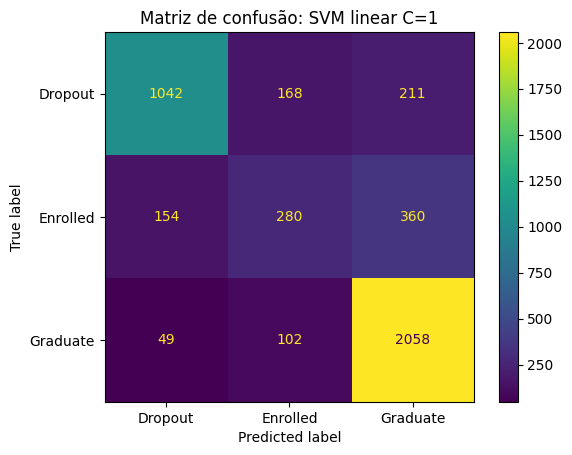

In [14]:
melhor = "linear C=1"
yt, yp = previsoes[melhor]
print(classification_report(yt, yp))
ConfusionMatrixDisplay.from_predictions(yt, yp)
plt.title(f"Matriz de confusão: SVM {melhor}")
plt.show()